In [11]:
# Load graph and set up training
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score
import matplotlib.pyplot as plt

np.random.seed(42)
torch.manual_seed(42)

npz_path = Path("processed_data/elliptic_graph.npz")
if npz_path.exists():
    graph = np.load(npz_path)
    x = graph["x"]
    edge_index = graph["edge_index"]
    y = graph["y"]
    train_mask = graph["train_mask"]
    val_mask = graph["val_mask"]
    test_mask = graph["test_mask"]
else:
    feature_columns = ["txId", "time_step"] + [f"feature_{i}" for i in range(1, 166)]
    features = pd.read_csv("elliptic_bitcoin_dataset/elliptic_txs_features.csv", header=None, names=feature_columns)
    classes = pd.read_csv("elliptic_bitcoin_dataset/elliptic_txs_classes.csv")
    classes["target"] = classes["class"].map({"1": 1, "2": 0})
    data_table = features.merge(classes[["txId", "target"]], on="txId", how="left", validate="one_to_one")
    tx_to_node = {tx_id: i for i, tx_id in enumerate(data_table["txId"])}
    edges = pd.read_csv("elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv")
    edges = edges[edges["txId1"].isin(tx_to_node) & edges["txId2"].isin(tx_to_node)]
    edge_index = edges[["txId1", "txId2"]].apply(lambda c: c.map(tx_to_node)).to_numpy(dtype=np.int64).T
    x = data_table[[f"feature_{i}" for i in range(1, 166)]].to_numpy(dtype=np.float32)
    y = data_table["target"].fillna(-1).to_numpy(dtype=np.int64)
    train_mask = (data_table["target"].notna() & (data_table["time_step"] <= 34)).to_numpy()
    val_mask = (data_table["target"].notna() & data_table["time_step"].between(35, 41)).to_numpy()
    test_mask = (data_table["target"].notna() & (data_table["time_step"] >= 42)).to_numpy()

data = Data(
    x=torch.tensor(x, dtype=torch.float32),
    edge_index=torch.tensor(edge_index, dtype=torch.long),
    y=torch.tensor(y, dtype=torch.long),
    train_mask=torch.tensor(train_mask, dtype=torch.bool),
    val_mask=torch.tensor(val_mask, dtype=torch.bool),
    test_mask=torch.tensor(test_mask, dtype=torch.bool),
)

if npz_path.exists() and "time_step" in graph:
    time_step = np.asarray(graph["time_step"])
else:
    labeled = pd.read_csv("processed_data/elliptic_labeled_processed.csv.gz")
    raw_features = pd.read_csv("elliptic_bitcoin_dataset/elliptic_txs_features.csv", header=None,
                               names=["txId", "time_step"] + [f"feature_{i}" for i in range(1, 166)])
    time_map = dict(zip(labeled["txId"], labeled["time_step"]))
    time_step = raw_features["txId"].map(time_map).fillna(-1).to_numpy(dtype=np.int64)

train_labels = data.y[data.train_mask].cpu().numpy()
counts = np.bincount(train_labels, minlength=2)
weights = torch.tensor(len(train_labels) / (2.0 * counts), dtype=torch.float32)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

In [12]:
# Shared illicit-class evaluation
def evaluate(y_true, probs, thr=0.5):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    pred = (probs >= thr).astype(int)
    return {
        "precision": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "PR-AUC": average_precision_score(y_true, probs),
        "ROC-AUC": roc_auc_score(y_true, probs),
    }

In [13]:
# 15 validation-only trials per model
class GCN(nn.Module):
    def __init__(self, num_features, hidden_channels, dropout, layers):
        super().__init__()
        convs = [GCNConv(num_features, hidden_channels)]
        convs += [GCNConv(hidden_channels, hidden_channels) for _ in range(layers - 2)]
        convs += [GCNConv(hidden_channels, 2)]
        self.convs = nn.ModuleList(convs)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.convs[-1](x, edge_index)

class GraphSAGE(nn.Module):
    def __init__(self, num_features, hidden_channels, dropout, layers):
        super().__init__()
        convs = [SAGEConv(num_features, hidden_channels)]
        convs += [SAGEConv(hidden_channels, hidden_channels) for _ in range(layers - 2)]
        convs += [SAGEConv(hidden_channels, 2)]
        self.convs = nn.ModuleList(convs)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.convs[-1](x, edge_index)

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def gnn_probs(model):
    model.eval()
    with torch.no_grad():
        logits = model(data.x.to(device), data.edge_index.to(device))
        return torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

def train_gnn(model_name, config, seed=42, max_epochs=120, patience=20):
    set_seed(seed)
    model_cls = GCN if model_name == "GCN" else GraphSAGE
    model = model_cls(data.num_node_features, config["hidden_channels"], config["dropout"], config["layers"])
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=weights.to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])

    x_dev = data.x.to(device)
    edge_dev = data.edge_index.to(device)
    y_dev = data.y.to(device)
    train_dev = data.train_mask.to(device)
    val_dev = data.val_mask.to(device)

    best_auc = -np.inf
    best_state = None
    bad_epochs = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(x_dev, edge_dev)
        loss = criterion(logits[train_dev], y_dev[train_dev])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(x_dev, edge_dev)
            train_loss = criterion(logits[train_dev], y_dev[train_dev]).item()
            val_loss = criterion(logits[val_dev], y_dev[val_dev]).item()
            val_probs = torch.softmax(logits[val_dev], dim=1)[:, 1].cpu().numpy()
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        val_auc = average_precision_score(y_dev[val_dev].cpu().numpy(), val_probs)
        if val_auc > best_auc + 1e-5:
            best_auc = val_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
        if bad_epochs >= patience:
            break

    model.load_state_dict(best_state)
    model = model.to(device)
    return model, gnn_probs(model), history, best_auc

rng = np.random.default_rng(42)
trial_rows = []
X = data.x.numpy()
y_all = data.y.numpy()
train_idx = data.train_mask.numpy()
val_idx = data.val_mask.numpy()
X_train, y_train = X[train_idx], y_all[train_idx]
X_val, y_val = X[val_idx], y_all[val_idx]

for model_name in ["GCN", "GraphSAGE"]:
    for _ in range(15):
        config = {
            "hidden_channels": int(rng.choice([32, 64, 128, 256])),
            "dropout": float(rng.uniform(0.2, 0.7)),
            "lr": float(10 ** rng.uniform(np.log10(1e-3), np.log10(1e-2))),
            "weight_decay": float(10 ** rng.uniform(np.log10(1e-5), np.log10(1e-3))),
            "layers": int(rng.choice([2, 3])),
        }
        _, probs, _, val_auc = train_gnn(model_name, config, seed=42)
        trial_rows.append({"model": model_name, "config": config, "val_PR_AUC": val_auc})

for _ in range(15):
    config = {
        "n_estimators": int(rng.integers(100, 501)),
        "max_depth": (lambda v: None if v is None else int(v))(rng.choice([None, 5, 10, 20, 30])),
        "min_samples_leaf": int(rng.choice([1, 2, 4, 8])),
    }
    model = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight="balanced", **config)
    model.fit(X_train, y_train)
    val_auc = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
    trial_rows.append({"model": "RandomForest", "config": config, "val_PR_AUC": val_auc})

for _ in range(15):
    config = {"C": float(10 ** rng.uniform(-4, 3))}
    model = make_pipeline(StandardScaler(), LogisticRegression(C=config["C"], class_weight="balanced", max_iter=1000, random_state=42))
    model.fit(X_train, y_train)
    val_auc = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
    trial_rows.append({"model": "LogisticRegression", "config": config, "val_PR_AUC": val_auc})

trials = pd.DataFrame(trial_rows)
best_configs = {m: rows.sort_values("val_PR_AUC", ascending=False).iloc[0].to_dict() for m, rows in trials.groupby("model")}
best_config_df = pd.DataFrame({"model": list(best_configs), "tuned_config": [best_configs[m]["config"] for m in best_configs], "val_PR_AUC": [best_configs[m]["val_PR_AUC"] for m in best_configs]})
print(best_config_df.to_string(index=False))

             model                                                                                                                            tuned_config  val_PR_AUC
               GCN {'hidden_channels': 256, 'dropout': 0.6163390980289187, 'lr': 0.005014932616908876, 'weight_decay': 4.214376026129217e-05, 'layers': 2}    0.622331
         GraphSAGE {'hidden_channels': 256, 'dropout': 0.4031934307200353, 'lr': 0.006516589805395809, 'weight_decay': 2.157475337005262e-05, 'layers': 3}    0.777773
LogisticRegression                                                                                                               {'C': 187.55359924017728}    0.587946
      RandomForest                                                                           {'n_estimators': 287, 'max_depth': 20, 'min_samples_leaf': 1}    0.931563


In [14]:
# Retrain each best configuration with seeds 42, 43, and 44
retrained_models = {}
retrained_val_probs = {}
retrained_train_probs = {}
retrained_histories = {}
seed_scores = {m: [] for m in best_configs}

for model_name in ["GCN", "GraphSAGE"]:
    probs_by_seed = []
    train_probs_by_seed = []
    for seed in [42, 43, 44]:
        model, val_probs, history, _ = train_gnn(model_name, best_configs[model_name]["config"], seed=seed)
        train_probs_seed = gnn_probs(model)[data.train_mask.numpy()]
        probs_by_seed.append(val_probs[data.val_mask.numpy()])
        train_probs_by_seed.append(train_probs_seed)
        retrained_models[(model_name, seed)] = model
        if seed == 42:
            retrained_histories[model_name] = history
        seed_scores[model_name].append(average_precision_score(y_val, val_probs[data.val_mask.numpy()]))
    retrained_val_probs[model_name] = np.mean(probs_by_seed, axis=0)
    retrained_train_probs[model_name] = np.mean(train_probs_by_seed, axis=0)

for model_name in ["RandomForest", "LogisticRegression"]:
    probs_by_seed = []
    train_probs_by_seed = []
    config = best_configs[model_name]["config"]
    for seed in [42, 43, 44]:
        if model_name == "RandomForest":
            model = RandomForestClassifier(random_state=seed, n_jobs=-1, class_weight="balanced", **config)
            model.fit(X_train, y_train)
            val_probs_seed = model.predict_proba(X_val)[:, 1]
            train_probs_seed = model.predict_proba(X_train)[:, 1]
        else:
            model = make_pipeline(StandardScaler(), LogisticRegression(C=config["C"], class_weight="balanced", max_iter=1000, random_state=seed))
            model.fit(X_train, y_train)
            val_probs_seed = model.predict_proba(X_val)[:, 1]
            train_probs_seed = model.predict_proba(X_train)[:, 1]
        probs_by_seed.append(val_probs_seed)
        train_probs_by_seed.append(train_probs_seed)
        retrained_models[(model_name, seed)] = model
        seed_scores[model_name].append(average_precision_score(y_val, val_probs_seed))
    retrained_val_probs[model_name] = np.mean(probs_by_seed, axis=0)
    retrained_train_probs[model_name] = np.mean(train_probs_by_seed, axis=0)

seed_table = pd.DataFrame({
    "model": list(seed_scores),
    "mean": [np.mean(seed_scores[m]) for m in seed_scores],
    "std": [np.std(seed_scores[m], ddof=1) for m in seed_scores],
})
seed_table["validation_PR_AUC"] = seed_table["mean"].map(lambda v: f"{v:.4f}") + " ± " + seed_table["std"].map(lambda v: f"{v:.4f}")
print(seed_table[["model", "validation_PR_AUC"]].to_string(index=False))

             model validation_PR_AUC
               GCN   0.6132 ± 0.0062
         GraphSAGE   0.7491 ± 0.0297
LogisticRegression   0.5879 ± 0.0000
      RandomForest   0.9302 ± 0.0012


In [15]:
# Freeze validation-selected thresholds
thresholds = {}
for model_name, probs in retrained_val_probs.items():
    candidates = np.linspace(0.0, 1.0, 1001)
    f1s = [f1_score(y_val, (probs >= t).astype(int), pos_label=1, zero_division=0) for t in candidates]
    thresholds[model_name] = float(candidates[int(np.argmax(f1s))])

             model  precision  recall     F1  PR-AUC  ROC-AUC
               GCN     0.4185  0.3211 0.3634  0.3012   0.7823
         GraphSAGE     0.8168  0.3824 0.5209  0.4843   0.8283
      RandomForest     0.8341  0.4681 0.5997  0.5485   0.8631
LogisticRegression     0.3351  0.4730 0.3923  0.2197   0.8456


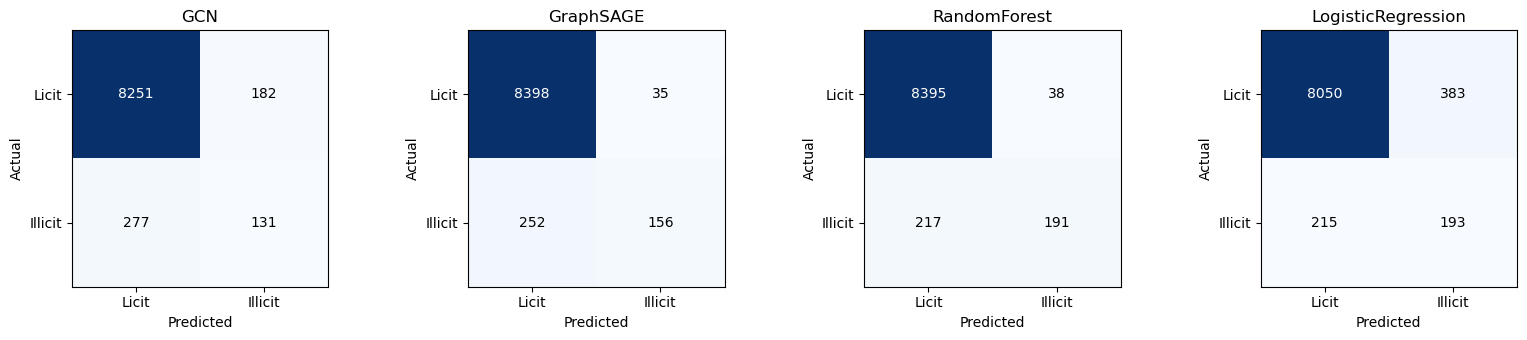

In [16]:
# Test-set metrics and confusion matrices
X_test = X[data.test_mask.numpy()]
y_test = y_all[data.test_mask.numpy()]
test_probs = {}

for model_name in ["GCN", "GraphSAGE"]:
    test_probs[model_name] = np.mean([
        gnn_probs(retrained_models[(model_name, seed)])[data.test_mask.numpy()]
        for seed in [42, 43, 44]
    ], axis=0)

for model_name in ["RandomForest", "LogisticRegression"]:
    test_probs[model_name] = np.mean([
        retrained_models[(model_name, seed)].predict_proba(X_test)[:, 1]
        for seed in [42, 43, 44]
    ], axis=0)

metrics_rows = []
for model_name, probs in test_probs.items():
    metrics = evaluate(y_test, probs, thresholds[model_name])
    metrics_rows.append({"model": model_name, **metrics})
test_metrics = pd.DataFrame(metrics_rows)
print(test_metrics.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, model_name in zip(axes, test_probs):
    pred = (test_probs[model_name] >= thresholds[model_name]).astype(int)
    cm = np.array([[np.sum((y_test == 0) & (pred == 0)), np.sum((y_test == 0) & (pred == 1))],
                   [np.sum((y_test == 1) & (pred == 0)), np.sum((y_test == 1) & (pred == 1))]])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(model_name)
    ax.set_xticks([0, 1], ["Licit", "Illicit"])
    ax.set_yticks([0, 1], ["Licit", "Illicit"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

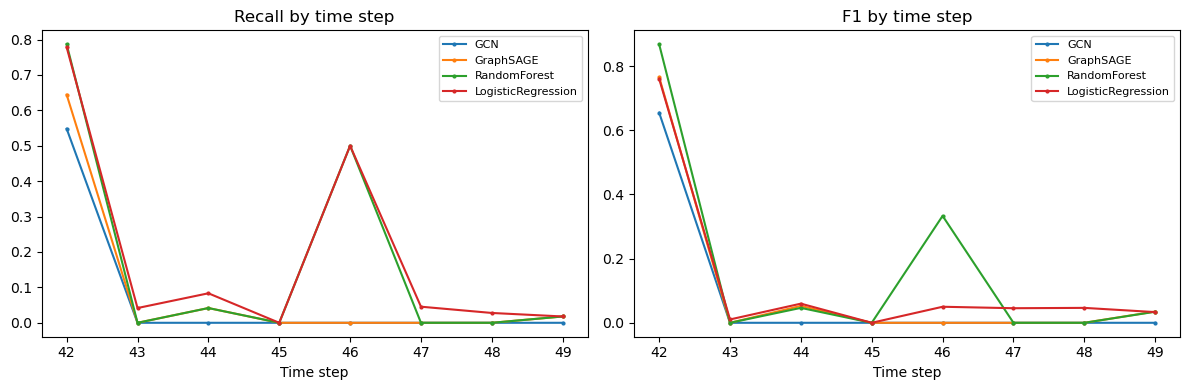

             model degree_group    n  n_illicit  precision  recall
               GCN          1-2 6593        360     0.4440  0.3417
               GCN           3+ 2248         48     0.2222  0.1667
         GraphSAGE          1-2 6593        360     0.8333  0.4167
         GraphSAGE           3+ 2248         48     0.5455  0.1250
      RandomForest          1-2 6593        360     0.8599  0.4944
      RandomForest           3+ 2248         48     0.5909  0.2708
LogisticRegression          1-2 6593        360     0.4218  0.4944
LogisticRegression           3+ 2248         48     0.0974  0.3125
               GCN          1-2 6593        360     0.4440  0.3417
               GCN           3+ 2248         48     0.2222  0.1667
         GraphSAGE          1-2 6593        360     0.8333  0.4167
         GraphSAGE           3+ 2248         48     0.5455  0.1250
      RandomForest          1-2 6593        360     0.8599  0.4944
      RandomForest           3+ 2248         48     0.5909  0.

In [17]:
# Test subgroup recall, F1, and degree precision
line_rows = []
degree_rows = []
edge_index_np = data.edge_index.numpy()
degree = np.bincount(edge_index_np[0], minlength=data.num_nodes) + np.bincount(edge_index_np[1], minlength=data.num_nodes)

def degree_group(d):
    if d == 0:
        return "0"
    if d <= 2:
        return "1-2"
    return "3+"

for model_name, probs in test_probs.items():
    pred = (probs >= thresholds[model_name]).astype(int)
    for step in sorted(np.unique(time_step[data.test_mask.numpy()])):
        if step < 0:
            continue
        step_mask = time_step[data.test_mask.numpy()] == step
        if step_mask.sum() == 0:
            continue
        line_rows.append({"model": model_name, "time_step": int(step), "recall": recall_score(y_test[step_mask], pred[step_mask], pos_label=1, zero_division=0), "F1": f1_score(y_test[step_mask], pred[step_mask], pos_label=1, zero_division=0)})

    test_nodes = np.flatnonzero(data.test_mask.numpy())
    test_degree = degree[test_nodes]
    degree_labels = np.select([test_degree == 0, test_degree <= 2], ["0", "1-2"], default="3+")

    for model_name, probs in test_probs.items():
        pred = (probs >= thresholds[model_name]).astype(int)
        for group in ["0", "1-2", "3+"]:
            group_mask = degree_labels == group
            if group_mask.sum() == 0:
                continue
            degree_rows.append({
                "model": model_name,
                "degree_group": group,
                "n": int(group_mask.sum()),
                "n_illicit": int(y_test[group_mask].sum()),
                "precision": precision_score(y_test[group_mask], pred[group_mask], pos_label=1, zero_division=0),
                "recall": recall_score(y_test[group_mask], pred[group_mask], pos_label=1, zero_division=0),
            })
line_df = pd.DataFrame(line_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name in test_probs:
    subset = line_df[line_df["model"] == model_name]
    axes[0].plot(subset["time_step"], subset["recall"], marker="o", markersize=2, label=model_name)
    axes[1].plot(subset["time_step"], subset["F1"], marker="o", markersize=2, label=model_name)
axes[0].set_title("Recall by time step")
axes[1].set_title("F1 by time step")
for ax in axes:
    ax.set_xlabel("Time step")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(pd.DataFrame(degree_rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

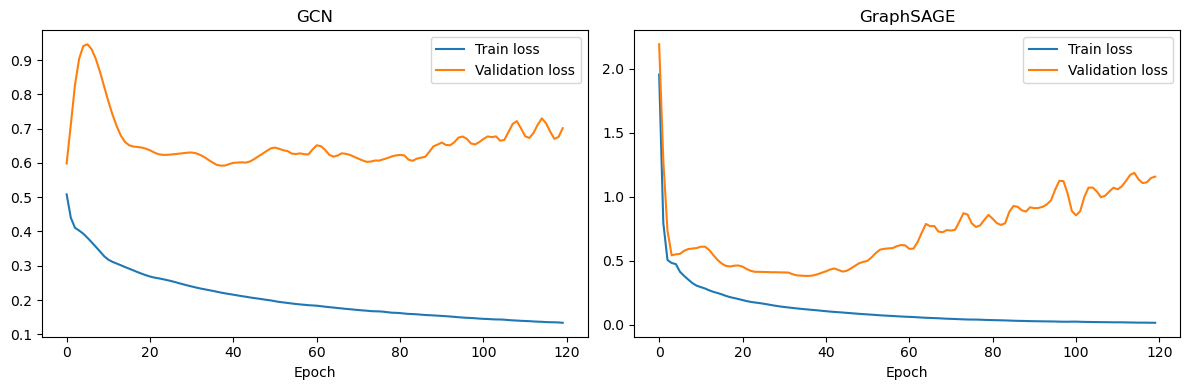

             model  train_PR_AUC  validation_PR_AUC
               GCN        0.9009             0.6190
         GraphSAGE        0.9875             0.7862
      RandomForest        1.0000             0.9308
LogisticRegression        0.9262             0.5879


In [18]:
# Training vs validation loss and PR-AUC
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model_name in zip(axes, ["GCN", "GraphSAGE"]):
    history = retrained_histories[model_name]
    ax.plot(history["train_loss"], label="Train loss")
    ax.plot(history["val_loss"], label="Validation loss")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.show()

overfit_rows = []
for model_name in retrained_val_probs:
    train_probs = retrained_train_probs[model_name]
    if model_name in ["GCN", "GraphSAGE"]:
        train_true = y_all[data.train_mask.numpy()]
    else:
        train_true = y_train
    overfit_rows.append({
        "model": model_name,
        "train_PR_AUC": average_precision_score(train_true, train_probs),
        "validation_PR_AUC": average_precision_score(y_val, retrained_val_probs[model_name]),
    })
print(pd.DataFrame(overfit_rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

In [19]:
# Final summary
summary_rows = []
for model_name in test_probs:
    test_row = test_metrics[test_metrics["model"] == model_name].iloc[0]
    val_row = seed_table[seed_table["model"] == model_name].iloc[0]
    summary_rows.append({
        "model": model_name,
        "tuned_config": str(best_configs[model_name]["config"]),
        "val_PR_AUC": val_row["mean"],
        "test_PR_AUC": test_row["PR-AUC"],
        "test_recall": test_row["recall"],
        "test_precision": test_row["precision"],
    })
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
best_model = summary.sort_values("test_PR_AUC", ascending=False).iloc[0]
print(f"Best model by test PR-AUC: {best_model['model']} ({best_model['test_PR_AUC']:.4f})")

             model                                                                                                                            tuned_config  val_PR_AUC  test_PR_AUC  test_recall  test_precision
               GCN {'hidden_channels': 256, 'dropout': 0.6163390980289187, 'lr': 0.005014932616908876, 'weight_decay': 4.214376026129217e-05, 'layers': 2}      0.6132       0.3012       0.3211          0.4185
         GraphSAGE {'hidden_channels': 256, 'dropout': 0.4031934307200353, 'lr': 0.006516589805395809, 'weight_decay': 2.157475337005262e-05, 'layers': 3}      0.7491       0.4843       0.3824          0.8168
      RandomForest                                                                           {'n_estimators': 287, 'max_depth': 20, 'min_samples_leaf': 1}      0.9302       0.5485       0.4681          0.8341
LogisticRegression                                                                                                               {'C': 187.55359924017728}      0.58